# Evaluación Parcial 2: Sign Language MNIST con CNN

Este notebook reutiliza las 24 clases estáticas de Sign Language MNIST de la EP1 y conserva la misma partición estratificada con semilla 42. La variante del grupo compara una CNN con el MLP `C_grande` bajo los mismos datos de entrenamiento, validación y test.

La CNN conserva cada imagen como un tensor de forma `28 x 28 x 1`. Esto permite que las capas convolucionales aprendan patrones locales, a diferencia del MLP, que recibe un vector plano de 784 valores.

## 1. Problema, objetivos y KPIs

El objetivo es clasificar una imagen estática de una seña ASL en una de las 24 letras disponibles. Se evaluarán accuracy, precision macro, recall macro, F1 macro y matriz de confusión. La comparación con la EP1 también considera cantidad de parámetros, tiempo de entrenamiento y diferencia entre validación y test.

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from sign_mlp.cnn import build_cnn, set_global_seed, training_callbacks
from sign_mlp.data import prepare_sign_mnist_cnn_data
from sign_mlp.evaluate import (
    plot_confusion,
    plot_feature_maps,
    plot_gradcam_examples,
    plot_history,
    plot_prediction_examples,
)

SEED = 42
EPOCHS = 20
BATCH_SIZE = 128
LEARNING_RATE = 0.001
set_global_seed(SEED)

## 2. Preparación de datos para CNN

Los píxeles se convierten a `float32` y se dividen por 255. La diferencia frente a la EP1 está en el formato: el MLP utiliza `(n, 784)` y la CNN utiliza `(n, 28, 28, 1)`. El último valor representa el canal de escala de grises.

In [2]:
data = prepare_sign_mnist_cnn_data(
    ROOT / "data" / "raw",
    validation_size=0.2,
    random_state=SEED,
)

X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]
index_to_label = data["index_to_label"]
class_names = data["metadata"]["class_names"]

print("Train:", X_train.shape, y_train.shape)
print("Validación:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Rango normalizado:", float(X_train.min()), float(X_train.max()))
print("Clases:", class_names)

Train: (21964, 28, 28, 1) (21964,)
Validación: (5491, 28, 28, 1) (5491,)
Test: (7172, 28, 28, 1) (7172,)
Rango normalizado: 0.0 1.0
Clases: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


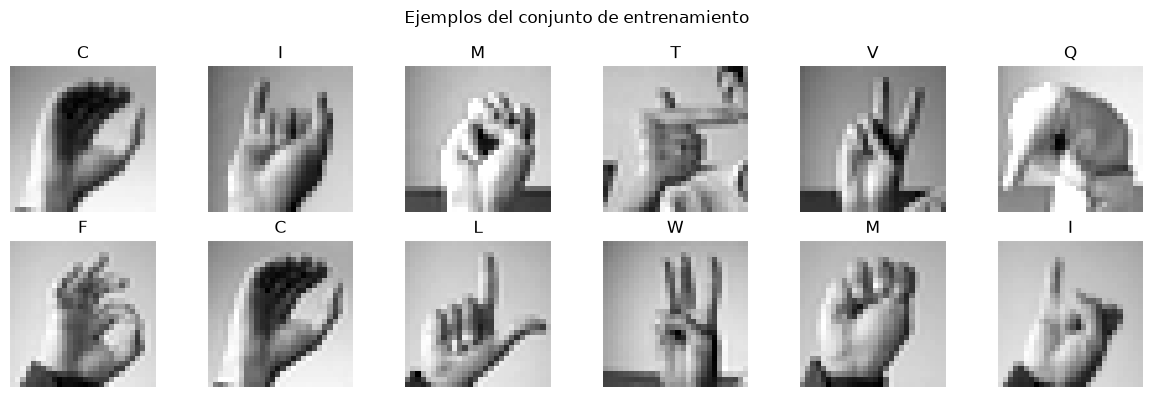

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for ax, image, label in zip(axes.flat, X_train[:12], y_train[:12]):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[int(label)])
    ax.axis("off")
fig.suptitle("Ejemplos del conjunto de entrenamiento")
fig.tight_layout()
plt.show()

## 3. Diseño de la CNN

La arquitectura utiliza tres bloques convolucionales con filtros `3 x 3`. Las capas aumentan de 32 a 128 filtros para aprender representaciones progresivamente más específicas. `MaxPooling2D` reduce el tamaño espacial y conserva las activaciones dominantes. Dropout reduce la dependencia de neuronas específicas. La capa softmax entrega una distribución sobre 24 clases.

In [4]:
model = build_cnn(
    input_shape=(28, 28, 1),
    num_classes=24,
    learning_rate=LEARNING_RATE,
    conv_dropout=0.25,
    dense_dropout=0.4,
)
model.summary()

Model: "sign_language_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_softmax (Dense)          │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,352 (950.59 KB)

 Trainable params: 243,352 (950.59 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento

Se mantiene un máximo de 20 épocas y batch 128 para conservar la trazabilidad con la EP1. Adam comienza con learning rate 0,001. `ReduceLROnPlateau` reduce el paso cuando la pérdida de validación se estanca y `EarlyStopping` conserva los mejores pesos según `val_loss`.

In [5]:
started = time.perf_counter()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=training_callbacks(patience=4),
    verbose=2,
)
fit_seconds = time.perf_counter() - started
print(f"Tiempo de entrenamiento: {fit_seconds:.2f} segundos")

Epoch 1/20


172/172 - 3s - 18ms/step - accuracy: 0.2683 - loss: 2.3968 - val_accuracy: 0.7565 - val_loss: 0.8933 - learning_rate: 0.0010


Epoch 2/20


172/172 - 2s - 13ms/step - accuracy: 0.7091 - loss: 0.8486 - val_accuracy: 0.9395 - val_loss: 0.2833 - learning_rate: 0.0010


Epoch 3/20


...

Epoch 20/20



Epoch 20: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.


172/172 - 2s - 13ms/step - accuracy: 0.9943 - loss: 0.0157 - val_accuracy: 1.0000 - val_loss: 7.5436e-05 - learning_rate: 2.5000e-04


Restoring model weights from the end of the best epoch: 19.


Tiempo de entrenamiento: 45.49 segundos


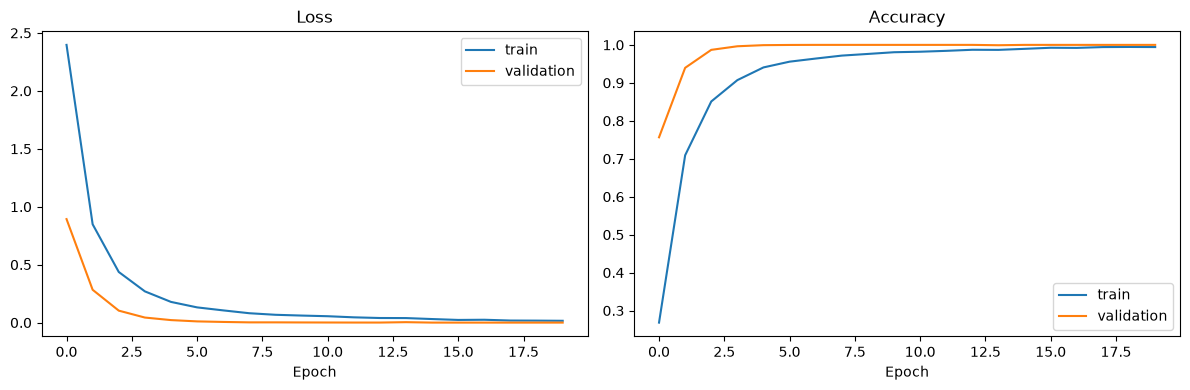

In [6]:
plot_history(history)
plt.show()

## 5. Evaluación de test

El test oficial se consulta después de fijar la arquitectura. Accuracy resume aciertos globales. Las métricas macro asignan el mismo peso a cada letra, aunque tengan cantidades distintas de ejemplos.

In [7]:
val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=0)
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
probabilities = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
predictions = np.argmax(probabilities, axis=1)

precision_macro = precision_score(y_test, predictions, average="macro", zero_division=0)
recall_macro = recall_score(y_test, predictions, average="macro", zero_division=0)
f1_macro = f1_score(y_test, predictions, average="macro", zero_division=0)

metrics = pd.Series({
    "accuracy_test": test_accuracy,
    "precision_macro": precision_macro,
    "recall_macro": recall_macro,
    "f1_macro": f1_macro,
    "loss_test": test_loss,
})
metrics

accuracy_test      0.965979
precision_macro    0.960429
recall_macro       0.961595
f1_macro           0.959519
loss_test          0.144418
dtype: float64

In [8]:
report_text = classification_report(
    y_test,
    predictions,
    target_names=class_names,
    zero_division=0,
)
print(report_text)

              precision    recall  f1-score   support

           A       1.00      1.00      1.00       331
           B       1.00      1.00      1.00       432
           C       1.00      1.00      1.00       310
           D       1.00      1.00      1.00       245
           E       0.96      1.00      0.98       498
           F       1.00      1.00      1.00       247
           G       0.94      0.91      0.92       348
           H       1.00      0.95      0.97       436
           I       0.96      1.00      0.98       288
           K       0.97      0.92      0.95       331
           L       0.85      1.00      0.92       209
           M       1.00      1.00      1.00       394
           N       1.00      1.00      1.00       291
           O       1.00      1.00      1.00       246
           P       1.00      1.00      1.00       347
           Q       0.83      1.00      0.91       164
           R       0.89      0.85      0.87       144
           S       1.00    

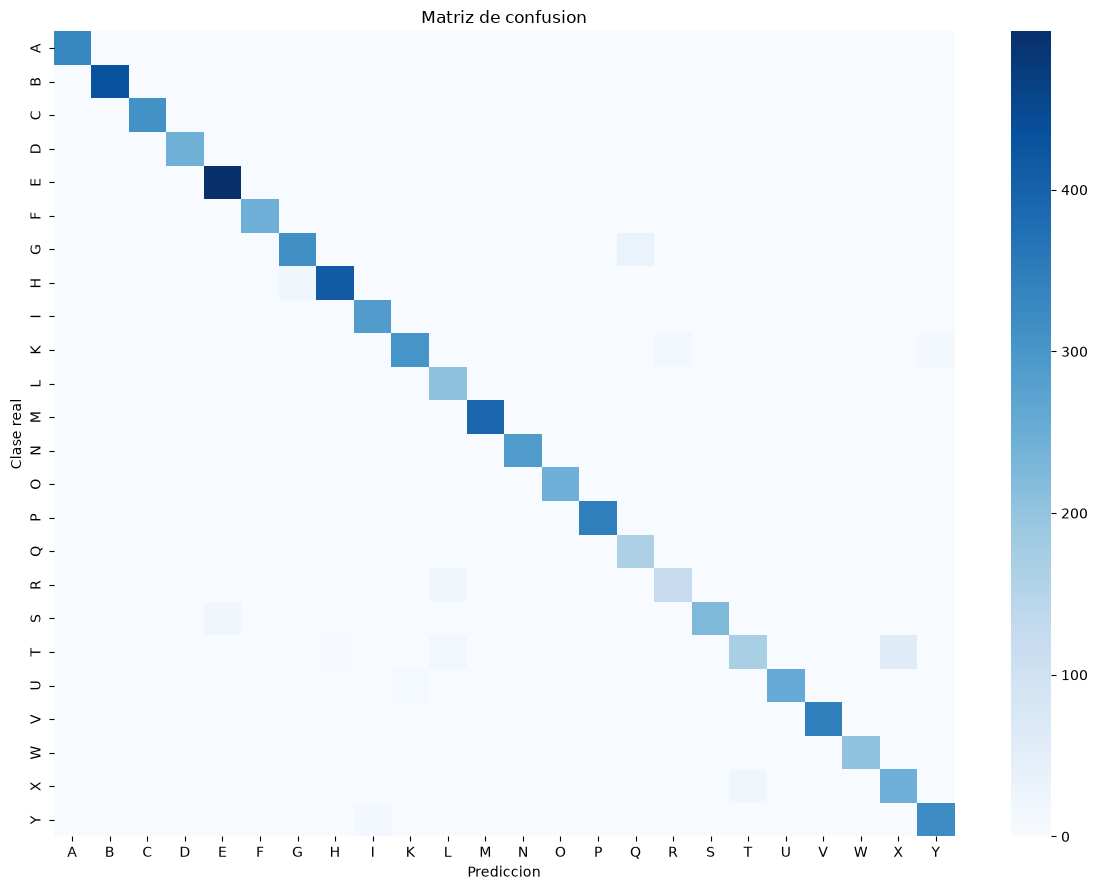

In [9]:
plot_confusion(y_test, predictions, index_to_label)
plt.show()

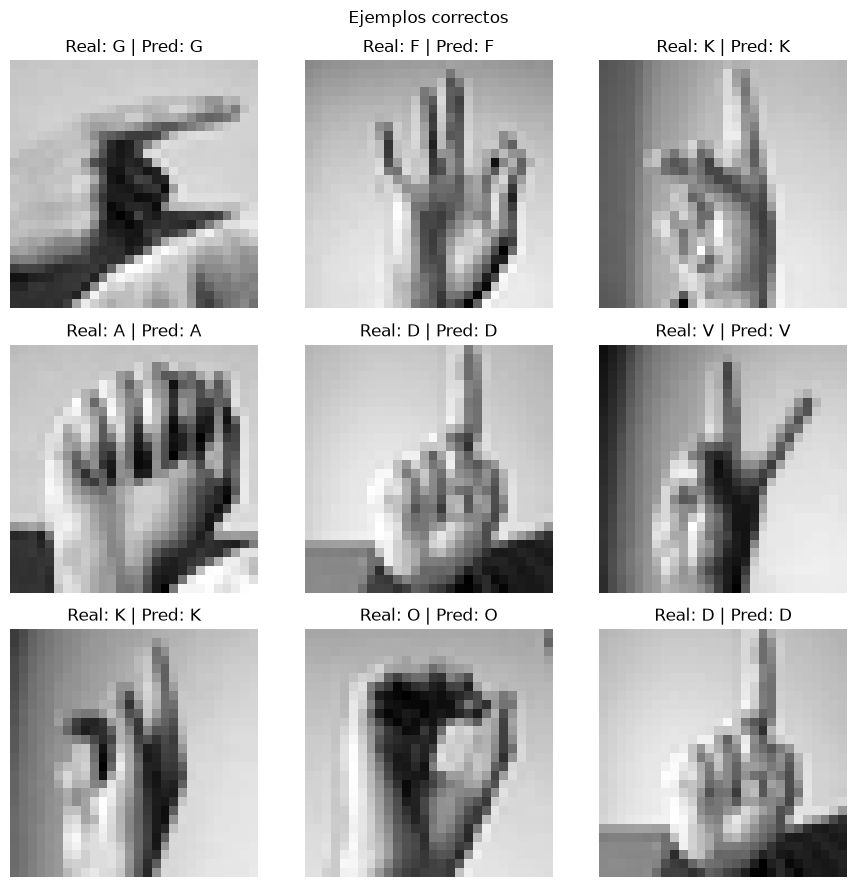

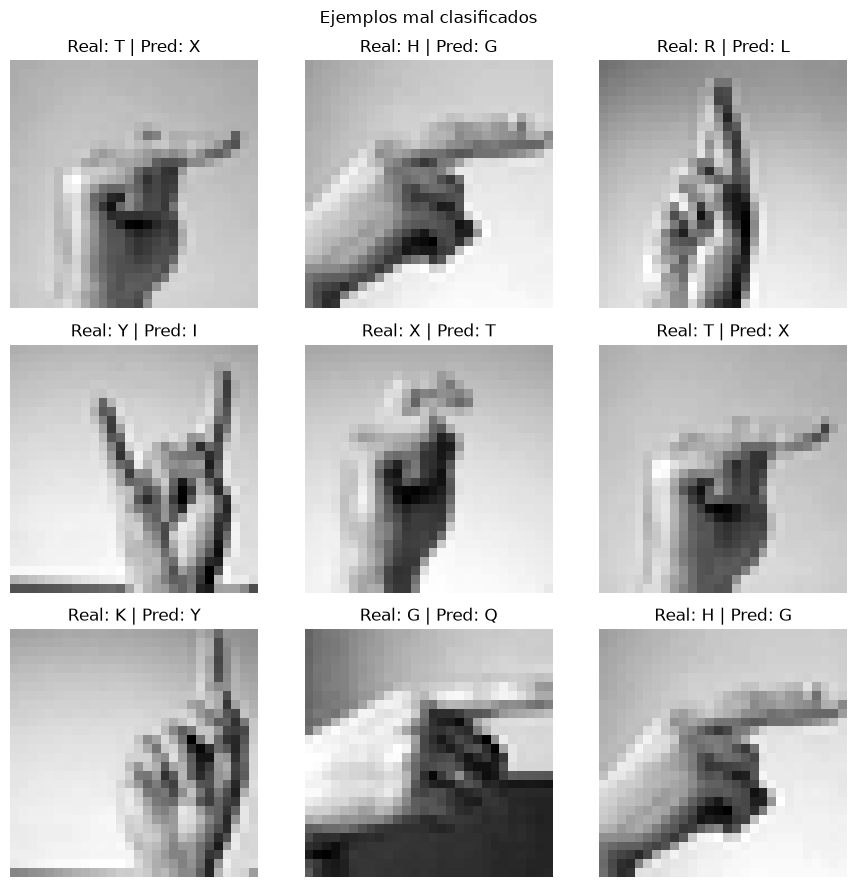

In [10]:
plot_prediction_examples(X_test, y_test, predictions, index_to_label, correct=True)
plt.show()
plot_prediction_examples(X_test, y_test, predictions, index_to_label, correct=False)
plt.show()

## 6. Feature maps y mapas de activación

Las primeras capas mantienen bordes, contrastes y trazos locales. Las capas profundas producen mapas más pequeños y selectivos. Grad-CAM resume qué regiones de la última capa convolucional aportaron a una clase predicha. Estos mapas orientan la interpretación, pero no prueban por sí solos una causa del acierto o error.

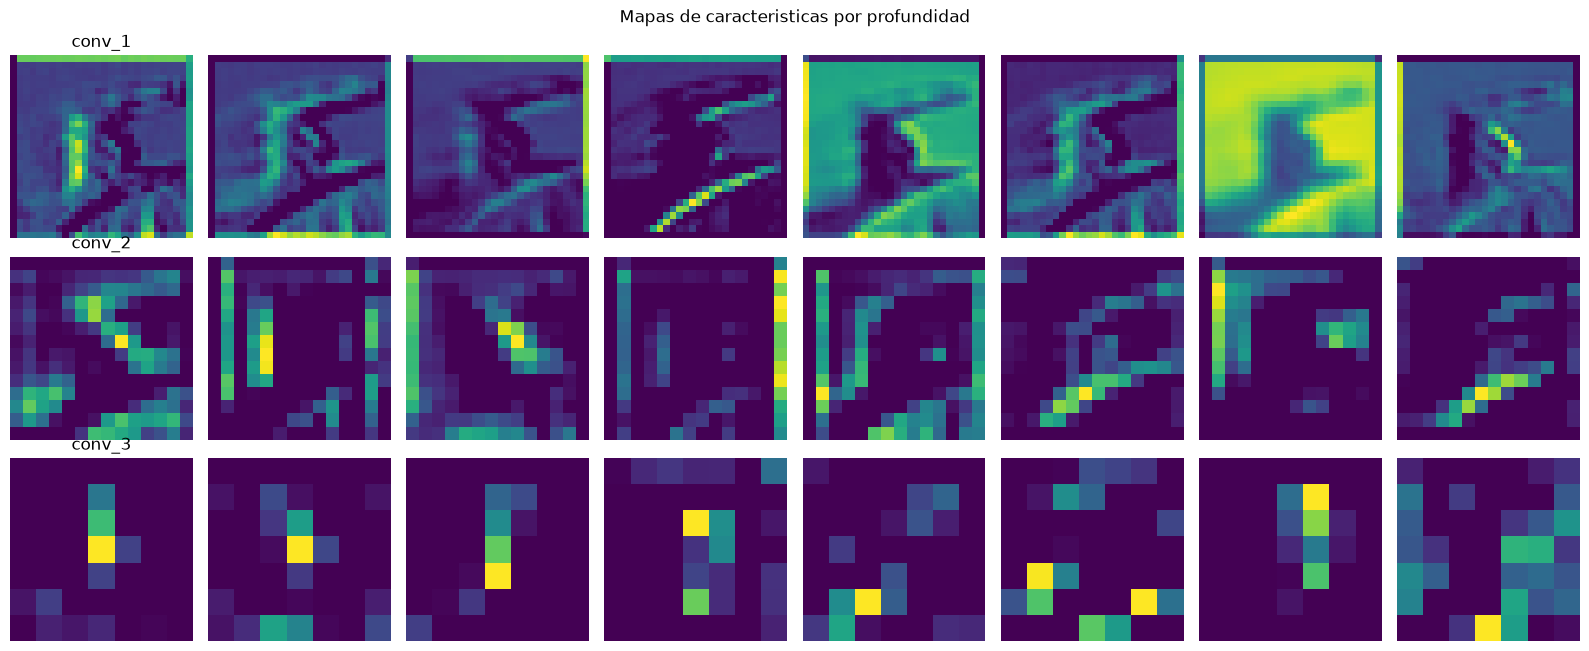

In [11]:
feature_index = int(np.where(y_test == predictions)[0][0])
plot_feature_maps(model, X_test[feature_index])
plt.show()

C:\tmp\ep2cnn-venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['imagen_28x28']
Received: inputs=Tensor(shape=(1, 28, 28, 1))
  warnings.warn(msg)


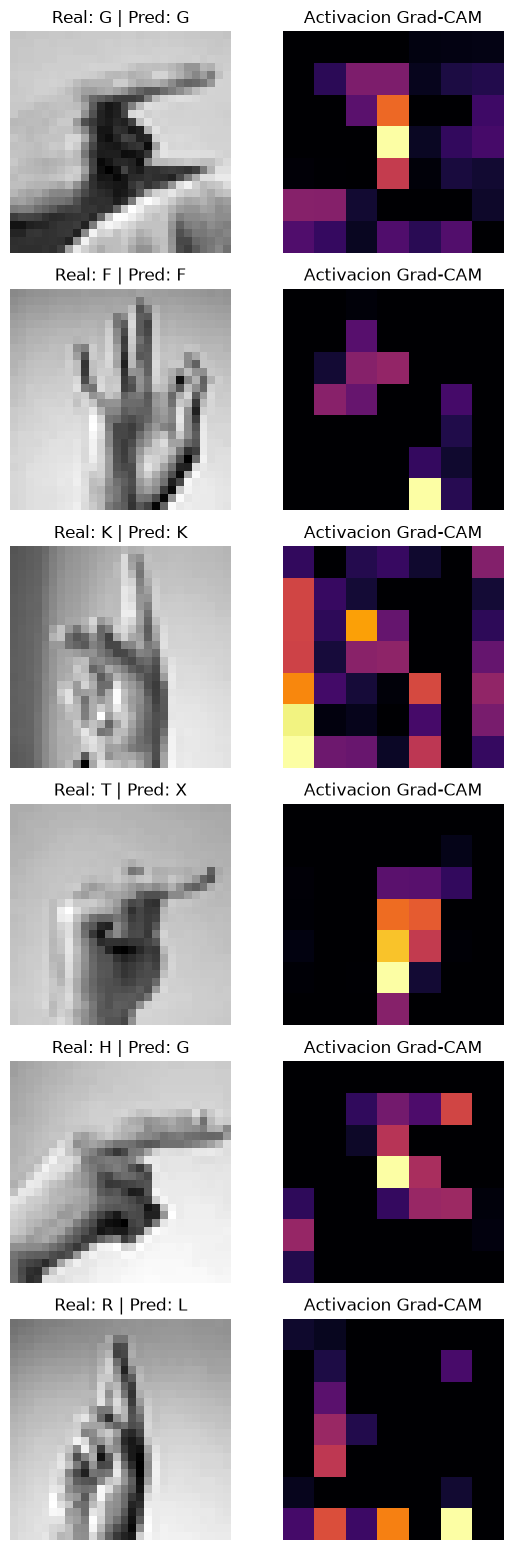

In [12]:
correct_indices = np.where(y_test == predictions)[0][:3]
wrong_indices = np.where(y_test != predictions)[0][:3]
selected = np.concatenate([correct_indices, wrong_indices])
plot_gradcam_examples(
    model,
    X_test[selected],
    y_test[selected],
    predictions[selected],
    index_to_label,
    max_items=len(selected),
)
plt.show()

## 7. Comparación experimental MLP y CNN

La referencia del MLP corresponde a la ejecución final de la EP1. Ambos modelos usan las mismas 24 clases y el mismo test oficial. La CNN tarda algo más en CPU, pero aprovecha la vecindad espacial y necesita menos parámetros que el MLP grande.

In [13]:
comparison = pd.DataFrame([
    {
        "model": "MLP C_grande (EP1)",
        "input_format": "vector 784",
        "parameters": 569240,
        "epochs_completed": 20,
        "fit_seconds": 31.5,
        "validation_accuracy": 1.0,
        "test_accuracy": 0.7971277237,
        "test_f1_macro": 0.7760310432,
    },
    {
        "model": "CNN (EP2)",
        "input_format": "tensor 28x28x1",
        "parameters": model.count_params(),
        "epochs_completed": len(history.history["loss"]),
        "fit_seconds": fit_seconds,
        "validation_accuracy": val_accuracy,
        "test_accuracy": test_accuracy,
        "test_f1_macro": f1_macro,
    },
])
comparison

,model,input_format,parameters,epochs_completed,fit_seconds,validation_accuracy,test_accuracy,test_f1_macro
0,MLP C_grande (EP1),vector 784,569240,20,31.500000,1.0,0.797128,0.776031
1,CNN (EP2),tensor 28x28x1,243352,20,45.492196,1.0,0.965979,0.959519


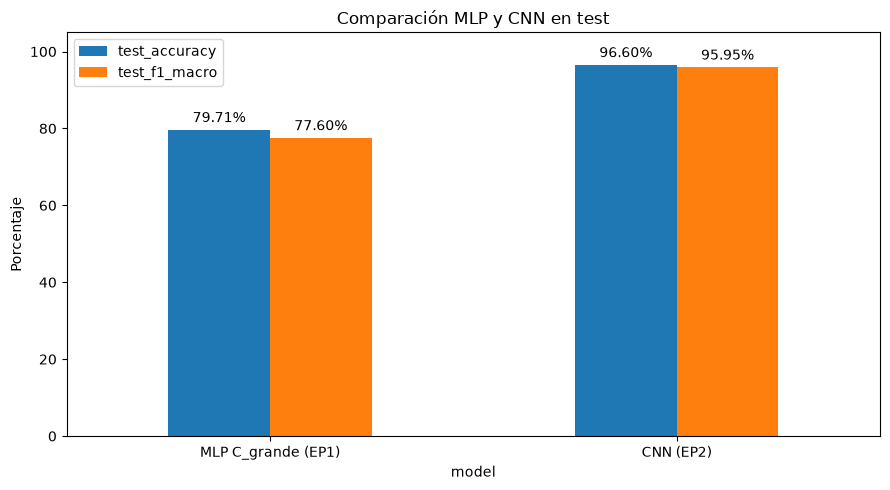

In [14]:
plot_data = comparison.set_index("model")[["test_accuracy", "test_f1_macro"]] * 100
ax = plot_data.plot(kind="bar", figsize=(9, 5), ylim=(0, 105))
ax.set_ylabel("Porcentaje")
ax.set_title("Comparación MLP y CNN en test")
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.show()

## 8. Conclusiones

La CNN mejora la generalización en el test porque sus filtros comparten pesos y buscan patrones locales en la imagen. El resultado no demuestra funcionamiento en cámaras, personas nuevas o señas en movimiento. Las clases con menor F1 y los ejemplos incorrectos deben revisarse antes de pensar en un uso educativo automático.

Como mejoras futuras se pueden comparar aumentación de datos, regularización L2 y otras profundidades, cambiando una variable a la vez y reservando una evaluación independiente.

In [15]:
reports_dir = ROOT / "reports"
images_dir = ROOT / "images"
models_dir = ROOT / "models"
for directory in (reports_dir, images_dir, models_dir):
    directory.mkdir(parents=True, exist_ok=True)

pd.DataFrame(history.history).to_csv(reports_dir / "cnn_history.csv", index_label="epoch")
comparison.to_csv(reports_dir / "mlp_cnn_comparison.csv", index=False)
(reports_dir / "cnn_classification_report.txt").write_text(report_text, encoding="utf-8")
notebook_metrics = {
    "model": "CNN_EP2",
    "seed": SEED,
    "parameters": int(model.count_params()),
    "fit_seconds": float(fit_seconds),
    "validation_loss": float(val_loss),
    "validation_accuracy": float(val_accuracy),
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(precision_macro),
    "test_recall_macro": float(recall_macro),
    "test_f1_macro": float(f1_macro),
}
(reports_dir / "cnn_metrics_notebook.json").write_text(
    json.dumps(notebook_metrics, indent=2, ensure_ascii=False),
    encoding="utf-8",
)
model.save(models_dir / "cnn_sign_language.keras")
print("Evidencias actualizadas en reports/, images/ y models/.")

Evidencias actualizadas en reports/, images/ y models/.
